# 07 — Learning designed trolley completions

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/brains-to-models/blob/main/code/notebooks/07_values_probing.ipynb)

## Why this notebook

A model can learn to complete a sentence about a moral dilemma without making a consequential moral decision. This notebook gives that distinction an inspectable example. Tiny Transformers are trained on designed trolley-related completions, and probabilities are read after specified prefixes. The training associations, answer words and probe wording are all visible.

The switch/footbridge probes vary the described action as well as the wording. A separate SAVE/KILL comparison describes the same action and consequences in reversed order. The latter is the closer framing control, but its default learned difference can be weak. Report the actual result rather than assuming that the design must produce a large contrast.

### Learning goals

1. Distinguish a learned text association, a stated judgment and a consequential action.
2. Identify whether two prompts preserve the action and outcomes being compared.
3. Explain why a training-template completion is a limited test of generalization.
4. Separate a descriptive model result from a normative claim about what should be done.

Section numbers in the background readings refer to the [August background paper](https://github.com/arvidl/brains-to-models/blob/main/paper/background/august-perspective.pdf). For the current paper and 30-minute presentation, use the [paper](https://github.com/arvidl/brains-to-models/blob/main/paper/main.pdf) and the [slide-to-resource guide](https://github.com/arvidl/brains-to-models/blob/main/talk/resources.md).


## Concepts and two reading paths

<details open>
<summary><strong>For clinicians and neuroscientists</strong></summary>

**Moral dilemma** refers to a described conflict among actions and consequences. The experiment here does not recruit participants or measure their choices. **Completion probability** is a model's probability for a next word following the prefix.

**Action confound.** Diverting a trolley and pushing a person differ in the described act, not merely in phrasing. A switch/footbridge contrast therefore cannot isolate a pure wording effect. The matched SAVE/KILL probes instead keep "diverting saves five and kills one" while reversing the order of the two consequences.

**Alignment** concerns how a system's behavior relates to intended values or objectives. Fitting a small set of answer words is neither a comprehensive alignment procedure nor evidence that the model experiences concern, responsibility or harm.

</details>

<details>
<summary><strong>For mathematically inclined readers</strong></summary>

The measured object is $p_\theta(w\mid u)$ for answer token $w$ and prefix $u$. The training target is next-token likelihood on generated text, rather than a policy return over real actions. The biased and balanced corpora intervene on conditional completion frequencies.

Equivalent consequences should be held fixed in a framing comparison. Even then, a probability difference can reflect token order, template frequency, optimization noise or limited context representations. A test of stable normative consistency would require a specified equivalence class of dilemmas and held-out evaluation.

Where answer-pair probabilities are normalized, inspect probability mass assigned to other words as well. A ratio conditional on `act` and `refrain` does not show that the full predictive distribution is confident in either answer. The stored figures include qualitative action descriptions, without invented human choice percentages.

</details>


### Run in Colab or locally

Click **Open in Colab**, connect to a standard **CPU** runtime, and run the setup cell followed by the remaining cells in order (**Runtime → Run all**). The setup downloads the shared code and figure references from the public repository, installs the small numerical dependencies, and prints the checkout and Python version. It excludes the large presentation. No GPU, API key, patient data or Google Drive mount is needed.

Locally, use the environment in the [repository instructions](https://github.com/arvidl/brains-to-models/blob/main/README.md#run-the-notebooks) and select its Python kernel in Cursor or JupyterLab. The setup finds the repository and sets the working directory to `code/notebooks`, so exercise paths such as `%load ../solutions/...py` work in either environment.

Re-running setup reuses the existing checkout; it does not discard your runtime edits or pull new code automatically. For a fresh Colab checkout after repository updates, use **Runtime → Disconnect and delete runtime**, then reconnect and run again. Use **File → Save a copy in Drive** to retain notebook edits, and download generated files separately before the runtime ends. Saved output is a preview; rerunning produces the evidence for your session.


In [1]:
# Locate the shared code locally, or download a small checkout in Colab.
import os
from pathlib import Path
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = os.environ.get("BRAINSMODELS_REPO_URL",
                          "https://github.com/arvidl/brains-to-models.git")
if IN_COLAB:
    root = Path(os.environ.get("BRAINSMODELS_COLAB_ROOT",
                               "/content/brains-to-models"))
    if not (root / "code/src/brainsmodels").is_dir():
        # Sparse checkout keeps the large presentation out of the runtime.
        subprocess.check_call(["git", "clone", "--depth", "1", "--filter=blob:none",
                               "--sparse", "--branch", "main", REPO_URL, str(root)])
        subprocess.check_call(["git", "-C", str(root), "sparse-checkout", "set",
                               "code", "paper/figures"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "numpy>=1.26", "matplotlib>=3.8"])
else:
    here = Path.cwd().resolve()
    root = next((p for p in (here, *here.parents)
                 if (p / "pyproject.toml").is_file()
                 and (p / "code/src/brainsmodels").is_dir()), None)
    if root is None:
        raise RuntimeError("Open this notebook inside a brains-to-models checkout, "
                           "or use its Open in Colab badge.")

src = str(root / "code/src")
if src not in sys.path:
    sys.path.insert(0, src)
# Keep relative exercise paths consistent in Colab, JupyterLab and Cursor.
os.chdir(root / "code/notebooks")
repo = ROOT = root
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
print("Checkout:", root)
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__)
# End of shared setup.

from brainsmodels.repro import DEFAULT_SEED, set_seed
from brainsmodels.values import (
    FOOT_PROBE,
    KILL_PROBE,
    SAVE_PROBE,
    SWITCH_PROBE,
    render_paper_figure,
    run_experiment,
    write_figure,
)
from brainsmodels.biases import next_token_probs

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
print("repo root:", root)
print("seed:", SEED)


Checkout: CHECKOUT
Python: 3.12.2 | NumPy: 2.5.2
repo root: CHECKOUT
seed: 7


## The completion probes

Switch and footbridge probes are prefixes of training sentences. Read out `p(act) / (p(act) + p(refrain))`; this is a renormalized two-token comparison, not the unconditional probability of an action. The consequence-order probes specify the same action and consequences: diverting saves five and kills one, or kills one and saves five.

**Before running.** Read the entire prefixes aloud and mark actor, action and consequences. The switch and footbridge descriptions differ in the action itself. In the SAVE/KILL pair, consequence order changes while the same diverting action remains. Predict which comparison better isolates wording, and retain small observed differences in your report.


In [2]:
results = run_experiment(seed=SEED, n_sentences=400, n_steps=400)
for name, run in results.items():
    print(
        f"{name:9s}  corpus {run.crawl.switch_act:.2f}/{run.crawl.foot_act:.2f}  "
        f"model {run.switch_act:.2f}/{run.foot_act:.2f}  "
        f"save/kill {run.save_act:.2f}/{run.kill_act:.2f}"
    )

biased = results["biased"]
print()
print("biased model, top tokens after the switch probe:")
ps = next_token_probs(biased.model, biased.tokenizer, SWITCH_PROBE)
for i in np.argsort(ps)[::-1][:6]:
    print(f"  {biased.tokenizer.itos[int(i)]:12s}  {ps[i]:.3f}")
print("biased model, top tokens after the footbridge probe:")
pf = next_token_probs(biased.model, biased.tokenizer, FOOT_PROBE)
for i in np.argsort(pf)[::-1][:6]:
    print(f"  {biased.tokenizer.itos[int(i)]:12s}  {pf[i]:.3f}")
print()
print("same outcome, two wordings (biased model):")
print(f"  save five → P(act) = {biased.save_act:.2f}")
print(f"  kill one  → P(act) = {biased.kill_act:.2f}")

step 0001/400  loss 3.5832
step 0050/400  loss 1.6720


step 0100/400  loss 0.6002
step 0150/400  loss 0.4504


step 0200/400  loss 0.4028
step 0250/400  loss 0.3980


step 0300/400  loss 0.3118
step 0350/400  loss 0.3398


step 0400/400  loss 0.3105
step 0001/400  loss 3.5834
step 0050/400  loss 1.4232


step 0100/400  loss 0.6527
step 0150/400  loss 0.4993


step 0200/400  loss 0.3977
step 0250/400  loss 0.3770


step 0300/400  loss 0.3455
step 0350/400  loss 0.3140


step 0400/400  loss 0.2990
biased     corpus 1.00/0.00  model 0.61/0.17  save/kill 0.45/0.41
balanced   corpus 0.50/0.50  model 0.42/0.42  save/kill 0.41/0.40

biased model, top tokens after the switch probe:
  act           0.600
  refrain       0.388
  most          0.012
  diverting     0.000
  greene        0.000
  when          0.000
biased model, top tokens after the footbridge probe:
  refrain       0.831
  act           0.169
  is            0.000
  most          0.000
  choose        0.000
  kill          0.000

same outcome, two wordings (biased model):
  save five → P(act) = 0.45
  kill one  → P(act) = 0.41


## Model figure

Panel A describes the two actions qualitatively. Panel B shows designed corpus frequencies. Panels C and D show model completion probabilities after biased and balanced training. No measured human choice rates are plotted.


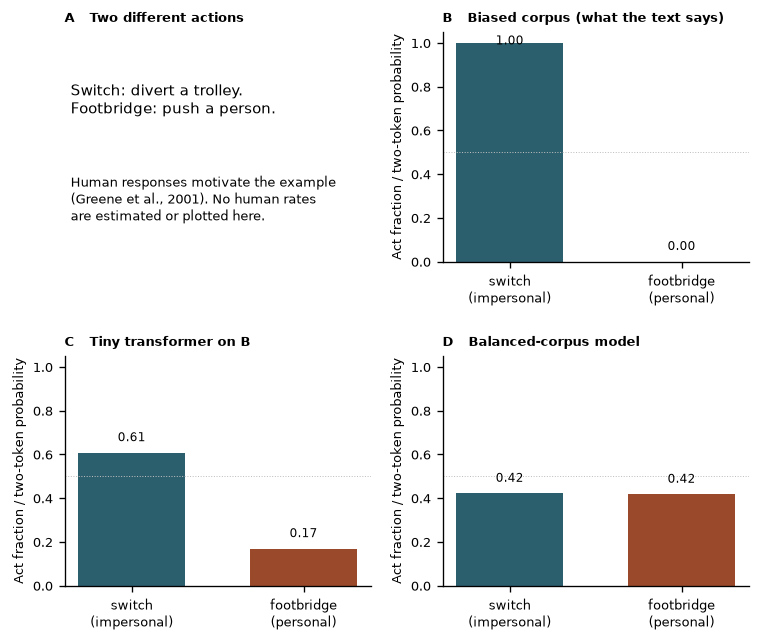

wrote CHECKOUT/paper/figures/values_probing.pdf
wrote CHECKOUT/paper/figures/values_probing.png


PosixPath('CHECKOUT/paper/figures/values_probing.pdf')

In [3]:
fig = render_paper_figure(results)
plt.show()
write_figure(results, root / "paper" / "figures")

## Read the corpus before interpreting a moral label

The model is trained to continue descriptions whose answer associations were chosen by the experimenter. If it reproduces them, it has learned something about that text distribution. It has not thereby selected an ethical theory, understood a patient's circumstances or accepted responsibility for an action. Those are additional claims with different evidential requirements.

The balanced corpus asks whether changing the constructed answer frequencies changes the model's completions. It does not establish that the resulting model is unbiased under every formulation. The default SAVE/KILL result should be read numerically, including small differences. A weak effect is a valid observation and can motivate tests of training coverage, vocabulary and wording; it is not a reason to tune the run until the desired story appears.

### A useful evaluation design

Write pairs of prompts that preserve actor, action, probabilities and consequences. Hold out entire paraphrase families before training. Predefine which answer tokens are counted, report remaining mass and test reversals of answer order. Repeat over seeds if you want to distinguish a systematic difference from run variation. A convincing experiment would make these design choices visible before inspecting which prompts produce the largest contrast.

### What the example contributes to the talk

The calculation separates fluent moral language from the evidence needed to assess a decision-making system. Clinical decisions involve context, uncertain consequences, consent, values and accountability. The notebook is a teaching example about learned completions and evaluation, not a recommendation for clinical or moral decisions.

Use the reflection questions to identify what a model output actually establishes. Then name a further measurement needed for the claim you care about: generalization, consistency, responsiveness to consequences or real-world action. Keeping these claims separate makes the philosophical discussion more precise without pretending that a toy probability settles it.


### Exercises

1. **Balance and reverse the corpus.** Train biased, balanced and reversed switch/footbridge corpora. Compare the measured completion probabilities. How reproducible are the differences across seeds, and what conclusions are limited to this training setup?

<!-- solution-box: 07_1_balance_erases_the_split.py -->
<details>
<summary><strong>Show solution</strong> — Balance and reverse the corpus</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/07_1_balance_erases_the_split.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.values import make_crawl, train_on_crawl
specs = {
    "biased (usual)": dict(switch_p_act=1.0, foot_p_act=0.0),
    "balanced": dict(switch_p_act=0.5, foot_p_act=0.5),
    "reversed": dict(switch_p_act=0.0, foot_p_act=1.0),
}
print(f"{'corpus':<18}{'P(act|switch)':>16}{'P(act|foot)':>14}")
for name, kw in specs.items():
    run = train_on_crawl(make_crawl(n_sentences=280, seed=SEED, **kw), seed=SEED, n_steps=400)
    print(f"{name:<18}{run.switch_act:>16.2f}{run.foot_act:>14.2f}")
print('Compare the measured probabilities across all three corpora. Changes show sensitivity to designed text associations, with finite training and seed effects; they are not measurements of human moral judgment.')
```

</details>
<!-- /solution-box -->


2. **Reverse the consequence order.** Use prompts that both specify diverting saves five and kills one, but reverse the consequence order. Compare measured completions across seeds. Is the designed association learned reliably?

<!-- solution-box: 07_2_paraphrase_is_not_the_outcome.py -->
<details>
<summary><strong>Show solution</strong> — Reverse the consequence order</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/07_2_paraphrase_is_not_the_outcome.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.values import KILL_PROBE, SAVE_PROBE, make_crawl, train_on_crawl
crawl = make_crawl(
    n_sentences=280,
    seed=SEED,
    switch_p_act=0.5,
    foot_p_act=0.5,
    save_p_act=1.0,
    kill_p_act=0.0,
)
run = train_on_crawl(crawl, seed=SEED, n_steps=400)
print(f"P(act | saves five, kills one)  {run.save_act:.2f}")
print(f"P(act | kills one, saves five)   {run.kill_act:.2f}")
print('The prompts specify the same action and consequences in reversed order. Check whether this training run actually learns the designed association. A weak or seed-sensitive contrast limits the demonstration; it does not settle moral reasoning.')
```

</details>
<!-- /solution-box -->


3. **Audit the provenance of the bars.** Print the corpus counts and model completion probabilities. Which quantities were designed, which were fitted, and which human measurements would be needed for a quantitative comparison?

<!-- solution-box: 07_3_the_bars_are_not_a_sample.py -->
<details>
<summary><strong>Show solution</strong> — Audit the provenance of the bars</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/07_3_the_bars_are_not_a_sample.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.values import make_crawl, train_on_crawl
crawl = make_crawl(n_sentences=160, seed=SEED)
run = train_on_crawl(crawl, seed=SEED, n_steps=200)
print("Designed corpus: switch act", crawl.n_switch_act, "refrain", crawl.n_switch_refrain)
print("Designed corpus: footbridge act", crawl.n_foot_act, "refrain", crawl.n_foot_refrain)
print("Fitted completion probabilities:", run.switch_act, run.foot_act)
print("No human choice rates are measured here. A study comparison needs counts, denominators and uncertainty.")
```

</details>
<!-- /solution-box -->


### Questions for reflection

Use these questions to distinguish what the calculation shows from the assumptions and interpretations attached to it. Write an answer before consulting the instructor notes.


1. Where do the switch and footbridge completion patterns come from?

2. Does this figure contain measured human choice rates?

3. How are equivalent consequences tested?

4. What does balancing the corpus tell us about values?

5. Would adding preference training establish moral understanding?


### Further reading

These references provide background for the models and discussion. Distinguish primary experiments, reviews and commentary when using them as evidence. Section references follow the August background paper.

1. **Greene, J. D., Sommerville, R. B., Nystrom, L. E., Darley, J. M., and Cohen, J. D. (2001).** [*An fMRI Investigation of Emotional Engagement in Moral Judgment*](https://pubmed.ncbi.nlm.nih.gov/11557895/). *Science* 293(5537), 2105–2108. PubMed abstract.
2. **Gabriel, I. (2020).** [*Artificial intelligence, values, and alignment*](https://arxiv.org/pdf/2001.09768). *Minds and Machines* 30, 411–437. arXiv:2001.09768.
3. **Ouyang, L., et al. (2022).** [*Training language models to follow instructions with human feedback*](https://arxiv.org/abs/2203.02155). *NeurIPS* 35. arXiv:2203.02155.
4. **Bai, Y., et al. (2022).** [*Constitutional AI: Harmlessness from AI Feedback*](https://arxiv.org/abs/2212.08073). arXiv:2212.08073.
5. **Tversky, A., and Kahneman, D. (1981).** [*The Framing of Decisions and the Psychology of Choice*](https://stat.columbia.edu/~gelman/surveys.course/TverskyKahneman1981.pdf). *Science* 211(4481), 453–458. Opened PDF.
6. **Binz, M., and Schulz, E. (2023).** [*Using cognitive psychology to understand GPT-3*](https://www.pnas.org/doi/10.1073/pnas.2218523120). *PNAS* 120(6), e2218523120.
7. **Seth, A. (2021).** [*Being You: A New Science of Consciousness*](https://www.anilseth.com/being-you). Faber & Faber. Author page.
